Predict the price of the **Uber ride** from a given pickup point to the agreed drop-off location.
Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [17]:
df = pd.read_csv("/content/uber.csv")
print("Initial Shape:", df.shape)
print("\nData Types:\n", df.dtypes)

Initial Shape: (200000, 9)

Data Types:
 Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object


In [18]:
df.isna().sum()
df.drop(columns=["Unnamed: 0", "key"], inplace=True)

In [4]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

df["year"] = df["pickup_datetime"].dt.year
df["month"] = df["pickup_datetime"].dt.month
df["day"] = df["pickup_datetime"].dt.day
df["hour"] = df["pickup_datetime"].dt.hour
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek

df.drop("pickup_datetime", axis=1, inplace=True)

In [5]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

print("\nShape after preprocessing:", df.shape)


Shape after preprocessing: (199996, 11)


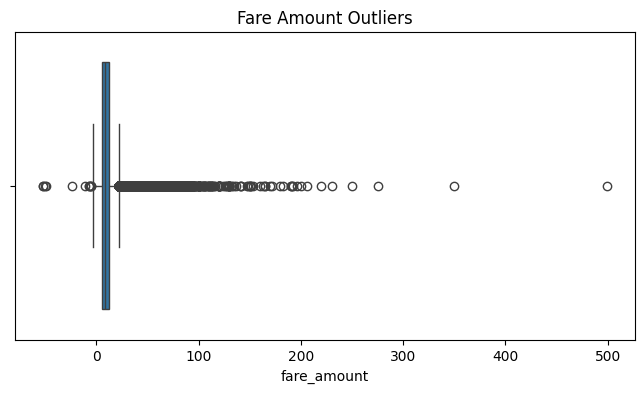

In [7]:
# OUTLIER DETECTION USING BOXPLOT
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount Outliers")
plt.show()

In [8]:
# OUTLIER TREATMENT USING IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[df["fare_amount"].between(lower, upper)]

print("\nShape after outlier removal:", df.shape)


Shape after outlier removal: (182830, 11)


In [9]:
# DISTANCE CALCULATION (EUCLIDEAN)
df["distance"] = np.sqrt(
    (df["pickup_longitude"] - df["dropoff_longitude"])**2 +
    (df["pickup_latitude"] - df["dropoff_latitude"])**2
)

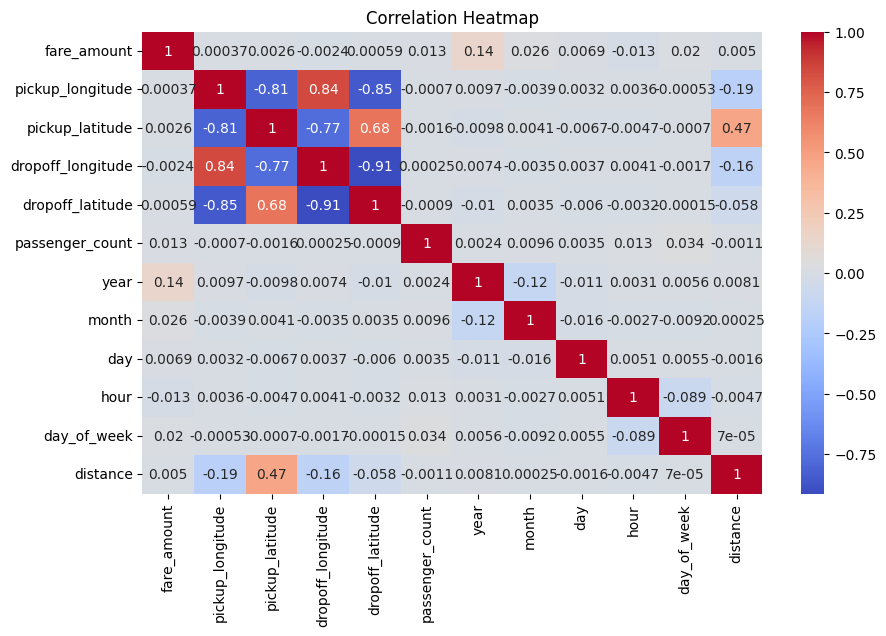

In [10]:
# CORRELATION
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [11]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [12]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)


In [13]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [14]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

print("\nMODEL COMPARISON:")
print(results)


MODEL COMPARISON:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.020627  4.085393  3.237346
1      Random Forest  0.754477  2.045530  1.382868
